# Лабораторная работа 2. Классификация. Нейронные сети

## Введение

### Цели и задачи

Цель работы: изучение методов классификации данных, реализованные в библиотеке Scikit-Learn, а также ознакомление с нейронными сетями с использованием библиотек TensorFlow и TensorBoard. 

Постановка задачи:

1. Необходимо выбрать и подготовить датасет для классификации, затем построить классификационные модели с помощью пяти методов:

    a. Наивный Байесовский классификатор (GaussianNB, MultinomialNB, ComplementNB, BernoulliNB);

    b. Деревья решений (Decision Tree);

    c. Линейный дискриминантный анализ (Linear Discriminant Analysis);

    d. Метод опорных векторов (Support Vector Machines);

    e. Метод ближайших соседей (k-Nearest Neighbors);

2. Затем сравните качество работы классификаторов с помощью следующих метрик:

    a. Accuracy (точность),

    b. Precision (доля правильно классифицированных положительных примеров),

    c. Recall (чувствительность, доля верно найденных положительных примеров),

    d. F1-Score (среднее гармоническое precision и recall),

    e. Площадь под кривой ROC (AUC-ROC).

3. Настройте гиперпараметры каждого метода и проведите исследование влияния различных параметров на качество классификации.

4. Реализуйте и протестируйте нейронную сеть на TensorFlow, исследуйте эффект настройки гиперпараметров и визуализируйте процесс обучения с помощью инструмента TensorBoard.

## Выбор и подготовка датасета

### Информация о выбранном датасете

В работе используется датасет Indian Liver Patient Dataset. Это реальные клинические данные 583 пациентов из северо-восточной части штата Андхра-Прадеш (Индия) - результаты лабораторных анализов крови. По результатам анализов крови определить, есть ли у пациента заболевание печени. 



1. `Age` - возраст пациента, лет  
2. `Gender` - пол пациента (Male/Female)   
3. `Total_Bilirubin` - общий билирубин, мг/дл   
4. `Direct_Bilirubin` - прямой (связанный) билирубин, мг/дл   
5. `Alkaline_Phosphotase` - щелочная фосфатаза, ед/л  
6. `Alamine_Aminotransferase` - аланинаминотрансфераза (АЛТ), ед/л  
7. `Aspartate_Aminotransferase` - аспартатаминотрансфераза (АСТ), ед/л   
8. `Total_Protiens` - общий белок, г/дл   
9. `Albumin` - альбумин, г/дл   
10. `Albumin_and_Globulin_Ratio` - отношение альбумина к глобулину   
11. `Dataset` - **целевая переменная**: `1` - заболевание печени, `2` - нет заболевания    
Итого: 10 признаков (9 числовых + пол) и 1 целевая переменная, 583 объекта.

### Импорт библиотек

In [20]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV,
    cross_validate, cross_val_score
)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay,
    balanced_accuracy_score
)

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

### Загрузка и первичный осмотр данных

In [21]:
df = pd.read_csv('indian_liver_patient.csv')
print('Размер таблицы (строк, столбцов):', df.shape)
df.head(10)

Размер таблицы (строк, столбцов): (583, 11)


,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1
5,46,Male,1.8,0.7,208,19,14,7.6,4.4,1.30,1
6,26,Female,0.9,0.2,154,16,12,7.0,3.5,1.00,1
7,29,Female,0.9,0.3,202,14,11,6.7,3.6,1.10,1
8,17,Male,0.9,0.3,202,22,19,7.4,4.1,1.20,2
9,55,Male,0.7,0.2,290,53,58,6.8,3.4,1.00,1


In [22]:
df.info()
df.describe().T.round(2)

<class 'pandas.DataFrame'>
RangeIndex: 583 entries, 0 to 582
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         583 non-null    int64  
 1   Gender                      583 non-null    str    
 2   Total_Bilirubin             583 non-null    float64
 3   Direct_Bilirubin            583 non-null    float64
 4   Alkaline_Phosphotase        583 non-null    int64  
 5   Alamine_Aminotransferase    583 non-null    int64  
 6   Aspartate_Aminotransferase  583 non-null    int64  
 7   Total_Protiens              583 non-null    float64
 8   Albumin                     583 non-null    float64
 9   Albumin_and_Globulin_Ratio  579 non-null    float64
 10  Dataset                     583 non-null    int64  
dtypes: float64(5), int64(5), str(1)
memory usage: 50.2 KB


,count,mean,std,min,25%,50%,75%,max
Age,583.0,44.75,16.19,4.0,33.0,45.00,58.0,90.0
Total_Bilirubin,583.0,3.30,6.21,0.4,0.8,1.00,2.6,75.0
Direct_Bilirubin,583.0,1.49,2.81,0.1,0.2,0.30,1.3,19.7
Alkaline_Phosphotase,583.0,290.58,242.94,63.0,175.5,208.00,298.0,2110.0
Alamine_Aminotransferase,583.0,80.71,182.62,10.0,23.0,35.00,60.5,2000.0
Aspartate_Aminotransferase,583.0,109.91,288.92,10.0,25.0,42.00,87.0,4929.0
Total_Protiens,583.0,6.48,1.09,2.7,5.8,6.60,7.2,9.6
Albumin,583.0,3.14,0.80,0.9,2.6,3.10,3.8,5.5
Albumin_and_Globulin_Ratio,579.0,0.95,0.32,0.3,0.7,0.93,1.1,2.8
Dataset,583.0,1.29,0.45,1.0,1.0,1.00,2.0,2.0


### Первичный анализ качества данных

In [23]:
df_raw = df.copy()
missing = df_raw.isna().sum().rename('Число пропусков').to_frame()
missing['Доля пропусков, %'] = (df_raw.isna().mean() * 100).round(2)
duplicate_count = int(df_raw.duplicated().sum())
display(missing.sort_values('Число пропусков', ascending=False))
print(f'Полных дубликатов строк: {duplicate_count}')

,Число пропусков,"Доля пропусков, %"
Albumin_and_Globulin_Ratio,4,0.69
Gender,0,0.00
Age,0,0.00
Total_Bilirubin,0,0.00
Direct_Bilirubin,0,0.00
Alamine_Aminotransferase,0,0.00
Alkaline_Phosphotase,0,0.00
Aspartate_Aminotransferase,0,0.00
Total_Protiens,0,0.00
Albumin,0,0.00


Полных дубликатов строк: 13


### Анализ целевой переменной

Распределение исходной целевой переменной Dataset

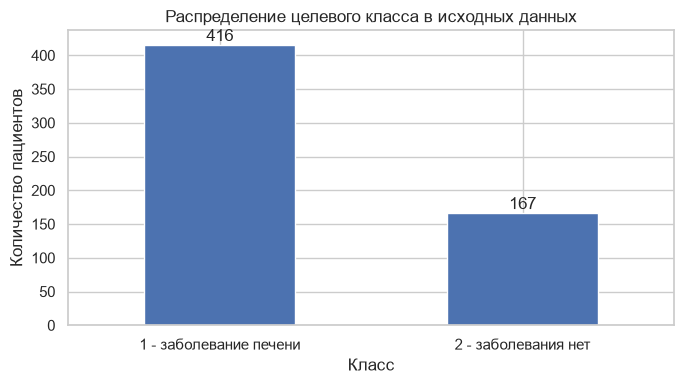

In [24]:
class_counts_raw = df_raw['Dataset'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 4))
labels = {1: '1 - заболевание печени', 2: '2 - заболевания нет'}
plot_counts = class_counts_raw.rename(index=labels)
plot_counts.plot(kind='bar', ax=ax)
ax.set_title('Распределение целевого класса в исходных данных')
ax.set_xlabel('Класс'); ax.set_ylabel('Количество пациентов')
ax.tick_params(axis='x', rotation=0)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom')
plt.tight_layout(); plt.show()

### Распределение признаков

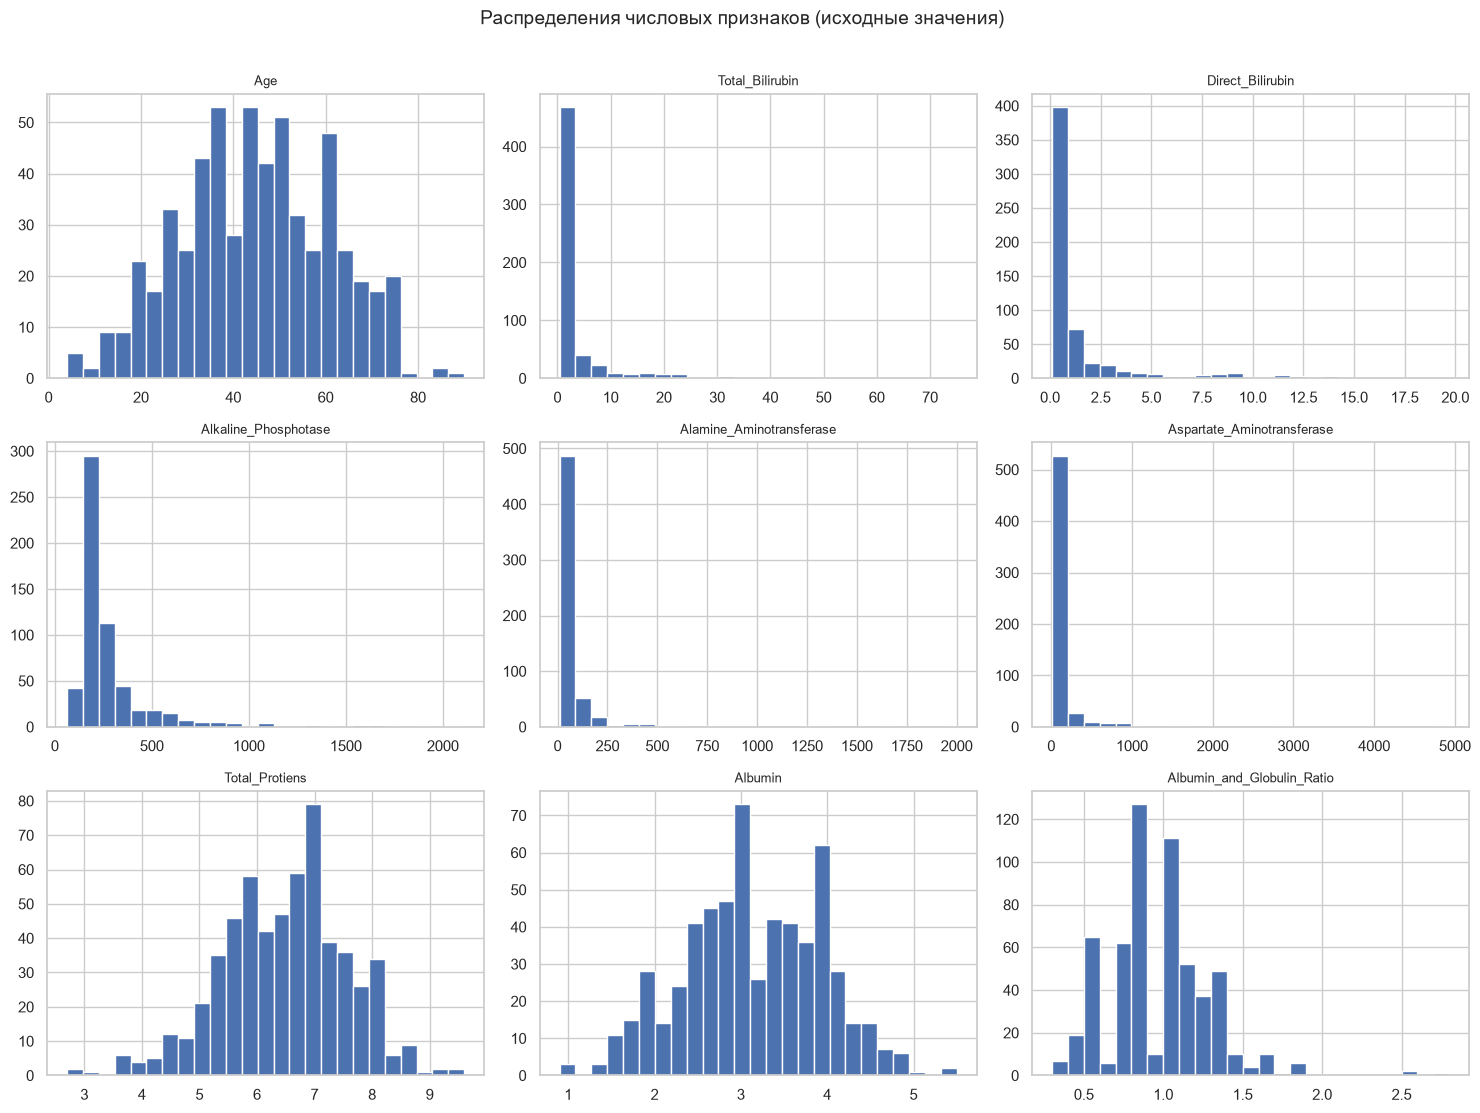

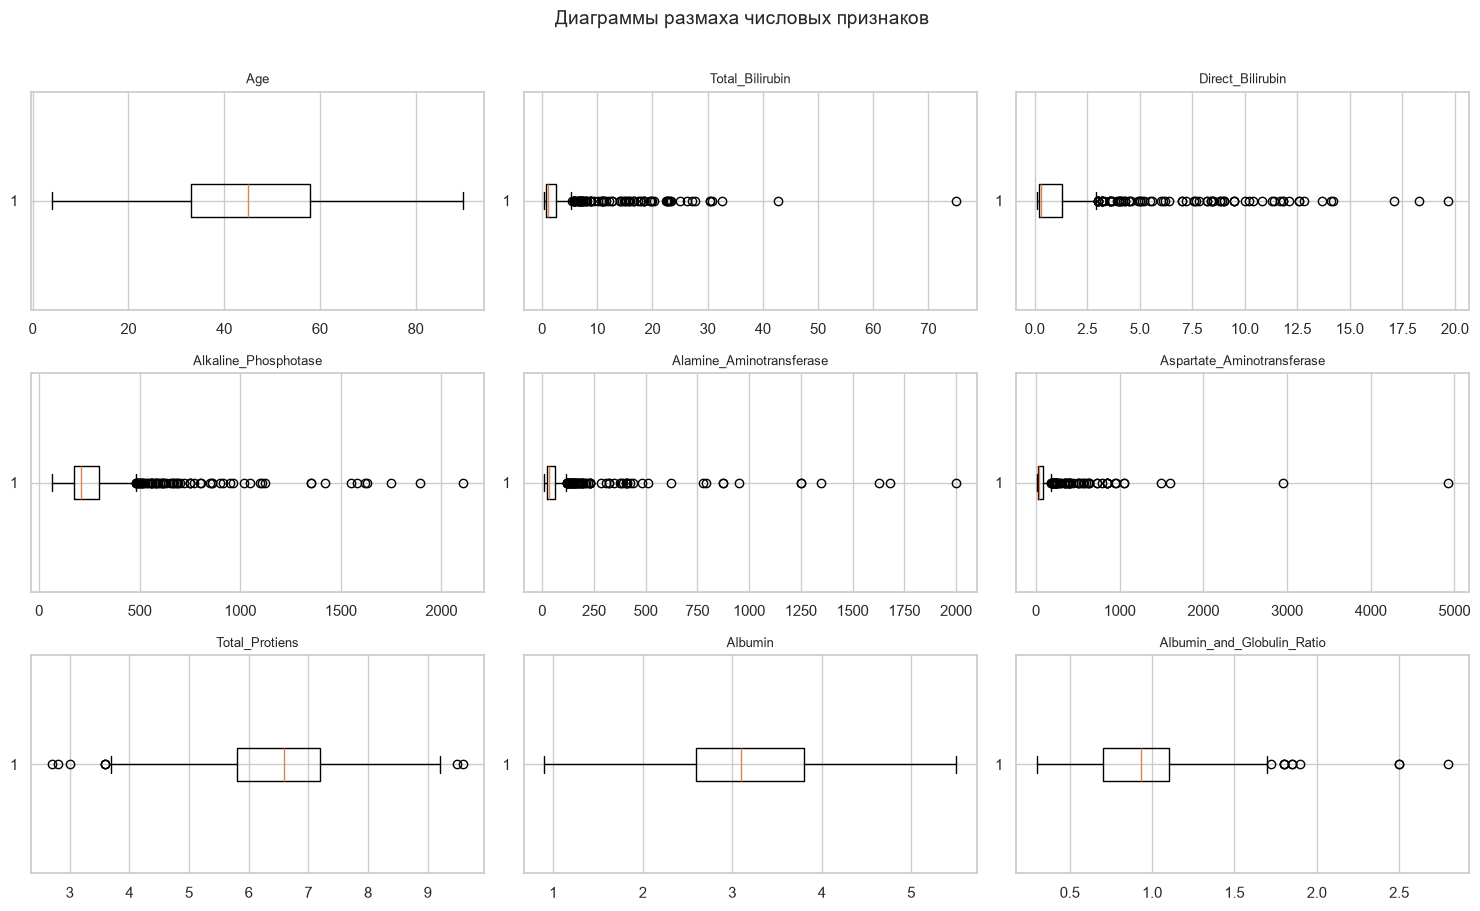

Признаки с наибольшей абсолютной асимметрией распределения:


,Асимметрия
Aspartate_Aminotransferase,10.546177
Alamine_Aminotransferase,6.549192
Total_Bilirubin,4.907474
Alkaline_Phosphotase,3.765106
Direct_Bilirubin,3.212403
Albumin_and_Globulin_Ratio,0.992299


In [25]:
numeric_cols_raw = df_raw.select_dtypes(include=np.number).columns.drop('Dataset', errors='ignore').tolist()
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.flat, numeric_cols_raw):
    ax.hist(df_raw[col].dropna(), bins=25, edgecolor='white')
    ax.set_title(col, fontsize=9)
    ax.set_xlabel('')
for ax in axes.flat[len(numeric_cols_raw):]:
    ax.axis('off')
fig.suptitle('Распределения числовых признаков (исходные значения)', y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

# Для компактного сравнения масштабы показаны отдельно на каждом subplot.
fig, axes = plt.subplots(3, 3, figsize=(15, 9))
for ax, col in zip(axes.flat, numeric_cols_raw):
    ax.boxplot(df_raw[col].dropna(), vert=False)
    ax.set_title(col, fontsize=9)
    ax.set_xlabel('')
for ax in axes.flat[len(numeric_cols_raw):]:
    ax.axis('off')
fig.suptitle('Диаграммы размаха числовых признаков', y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

skewness = df_raw[numeric_cols_raw].skew(numeric_only=True).sort_values(key=lambda s: s.abs(), ascending=False)
print('Признаки с наибольшей абсолютной асимметрией распределения:')
display(skewness.to_frame('Асимметрия').head(6))

### Предобработка данных

In [26]:
# 1. Удаляем полные дубликаты до разделения на train/test.
n_before = len(df_raw)
data = df_raw.drop_duplicates().reset_index(drop=True).copy()
removed_duplicates = n_before - len(data)

# 1 = заболевание, 0 = заболевания нет.
data['target'] = data['Dataset'].map({1: 1, 2: 0})
if data['target'].isna().any():
    raise ValueError('В Dataset обнаружены неожиданные значения, отличные от 1 и 2.')
data = data.drop(columns='Dataset')

# 3. Кодируем бинарный признак пола: Male=1, Female=0.
unknown_gender = set(data['Gender'].dropna().unique()) - {'Male', 'Female'}
if unknown_gender:
    raise ValueError(f'Неизвестные значения Gender: {unknown_gender}')
data['Gender'] = data['Gender'].map({'Female': 0, 'Male': 1}).astype(float)

X = data.drop(columns='target')
y = data['target'].astype(int)

print(f'Исходных строк: {n_before}')
print(f'Удалено полных дубликатов: {removed_duplicates}')
print(f'Строк после удаления дубликатов: {len(data)}')
print(f'Входных признаков: {X.shape[1]}')
print('Пропуски после удаления дубликатов (будут заполнены в Pipeline):')
display(X.isna().sum().rename('Пропусков').to_frame().query('Пропусков > 0'))
print('Целевой класс после очистки (1 = заболевание; 0 = нет заболевания):')
class_counts = y.value_counts().sort_index()
display(pd.DataFrame({'Количество': class_counts, 'Доля, %': (100*class_counts/len(y)).round(2)}).rename(index={0:'0 — нет заболевания', 1:'1 — заболевание'}))

Исходных строк: 583
Удалено полных дубликатов: 13
Строк после удаления дубликатов: 570
Входных признаков: 10
Пропуски после удаления дубликатов (будут заполнены в Pipeline):


,Пропусков
Albumin_and_Globulin_Ratio,4


Целевой класс после очистки (1 = заболевание; 0 = нет заболевания):


,Количество,"Доля, %"
target,,
0 — нет заболевания,164,28.77
1 — заболевание,406,71.23


## Разбиение выборки

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

split_summary = pd.DataFrame({
    'Объектов': [len(X_train), len(X_test), len(X)],
    'Заболевание (1)': [int(y_train.sum()), int(y_test.sum()), int(y.sum())],
    'Нет заболевания (0)': [int((y_train == 0).sum()), int((y_test == 0).sum()), int((y == 0).sum())],
    'Доля заболевания, %': [100*y_train.mean(), 100*y_test.mean(), 100*y.mean()],
}, index=['Обучающая выборка', 'Тестовая выборка', 'Всего']).round(2)
display(split_summary)
print('Проверка размера:', X_train.shape, X_test.shape)
assert set(X_train.index).isdisjoint(set(X_test.index))

,Объектов,Заболевание (1),Нет заболевания (0),"Доля заболевания, %"
Обучающая выборка,456,325,131,71.27
Тестовая выборка,114,81,33,71.05
Всего,570,406,164,71.23


Проверка размера: (456, 10) (114, 10)


## Методы классификации 

### Описание методов классификации

### Наивный байесовский классификатор 
Строится на теореме Байеса: $P(y\mid x) \propto P(y)\prod_{j} P(x_j\mid y)$. «Наивность» - допущение, что признаки **условно независимы** при заданном классе. Это резко упрощает оценку параметров (нужны лишь одномерные распределения) и делает метод очень быстрым и устойчивым на малых выборках, но допущение нарушается при коррелированных признаках (у нас: билирубины, АЛТ/АСТ, белок/альбумин).
Варианты различаются предположением о распределении $P(x_j\mid y)$:
- **GaussianNB** - признаки непрерывные и нормальные внутри класса. Гиперпараметр `var_smoothing` - доля максимальной дисперсии, добавляемая ко всем дисперсиям для численной устойчивости (сглаживание). Логичный выбор для наших непрерывных признаков.
- **MultinomialNB** - признаки - неотрицательные «счётчики» (классически частоты слов). Гиперпараметры: `alpha` (сглаживание Лапласа), `fit_prior` (учитывать ли априорные вероятности классов). Требует неотрицательных входов, поэтому признаки масштабируются в [0, 1].
- **ComplementNB** - модификация Multinomial, оценивающая параметры по **дополнению** класса (всем остальным); создана для несбалансированных данных. Гиперпараметры: `alpha`, `norm`.
- **BernoulliNB** - признаки бинарны («есть / нет»); непрерывные значения бинаризуются порогом `binarize`. Гиперпараметры: `alpha`, `binarize`.

### Дерево решений (Decision Tree)
Рекурсивно делит пространство признаков порогами вида «признак ≤ значение», выбирая на каждом шаге разбиение, которое сильнее всего уменьшает **неоднородность** узла (критерии `gini` или `entropy`/`log_loss`). Лист выдаёт долю класса. Метод интерпретируем, не требует масштабирования, умеет ловить нелинейности и взаимодействия, но **склонен к переобучению**: неограниченное дерево запоминает обучающую выборку. Ключевые гиперпараметры: `max_depth`, `min_samples_leaf`, `criterion`, `ccp_alpha` (обрезка по сложности), `class_weight`.

### Линейный дискриминантный анализ (LDA)
Предполагает, что внутри каждого класса признаки имеют нормальное распределение с **общей для классов ковариационной матрицей**. Тогда оптимальная граница по Байесу - **гиперплоскость**; LDA одновременно ищет направление, максимально разделяющее классы (критерий Фишера). Гиперпараметры: `solver` (`svd`, `lsqr`, `eigen`), `shrinkage` (регуляризация ковариационной матрицы - полезна при коррелированных признаках; доступна для `lsqr`/`eigen`; `'auto'` - оценка Ледойта-Вольфа), `priors` (априорные вероятности классов - сдвигают порог).

### Метод опорных векторов (SVM)
Находит разделяющую гиперплоскость с **максимальным зазором** между классами; «мягкий» зазор допускает ошибки со штрафом `C` (большой `C` - меньше ошибок на обучении, но выше риск переобучения). С помощью **ядер** (`linear`, `poly`, `rbf`, `sigmoid`) строится нелинейная граница. У RBF-ядра параметр `gamma` задаёт «радиус влияния» объекта (большая `gamma` - очень локальная, «изрезанная» граница). Метод чувствителен к масштабу признаков. `class_weight='balanced'` увеличивает штраф за ошибки на редком классе.

### Метод ближайших соседей (kNN)
«Ленивый» метод: при предсказании находит `k` ближайших обучающих объектов и голосует (возможно, с весами обратно пропорциональными расстоянию). Гиперпараметры: `n_neighbors` (малое `k` - шумная граница и переобучение, большое - сильное сглаживание и вырождение к большинству), `weights` (`uniform` / `distance`), `metric` (евклидова, манхэттенская, Чебышёва, Минковского). Очень чувствителен к масштабу признаков и «проклятию размерности».

### Метрики качества
Пусть положительный класс - «болен»; TP, FP, TN, FN - число верно/неверно найденных больных и здоровых.
- **Accuracy** = (TP + TN) / (TP + TN + FP + FN) - доля верных ответов; при дисбалансе 71/29 тривиальный ответ «все больны» даёт ≈ 0.71.
- **Precision** = TP / (TP + FP) - если модель сказала «болен», как часто это правда.
- **Recall** = TP / (TP + FN) - какую долю реально больных модель нашла. В медицине пропуск больного (FN) обычно опаснее ложной тревоги, поэтому Recall особенно важен.
- **F1** = 2·Precision·Recall / (Precision + Recall) - гармоническое среднее. Для положительного (преобладающего) класса легко завышается тривиальной моделью (при ответе «все больны» F1 = 0.83).
- **ROC-AUC** - площадь под кривой «TPR от FPR» при всех возможных порогах; вероятность того, что случайный больной получит оценку выше, чем случайный здоровый. 0.5 - случайное угадывание, 1.0 - идеал. Не зависит от порога и дисбаланса.
- Дополнительно в сравнении используется **Specificity** = TN / (TN + FP) - доля верно опознанных здоровых; она показывает, «не отвечает ли» модель всем подряд «болен».

### Обучение модели

In [28]:
def make_pipeline(estimator, scaling='standard'):
    """Импутация обучающей медианой + выбранное масштабирование + модель."""
    steps = [('imputer', SimpleImputer(strategy='median'))]
    if scaling == 'standard':
        steps.append(('scaler', StandardScaler()))
    elif scaling == 'minmax':
        steps.append(('scaler', MinMaxScaler()))
    elif scaling != 'none':
        raise ValueError("scaling должен быть 'standard', 'minmax' или 'none'")
    steps.append(('classifier', estimator))
    return Pipeline(steps)


def get_score(model, X_part):
    """Скор для ROC-AUC: вероятность класса 1 или decision_function."""
    if hasattr(model, 'predict_proba'):
        proba = model.predict_proba(X_part)
        classes = list(model.classes_) if hasattr(model, 'classes_') else None
        if classes is not None and 1 in classes:
            return proba[:, classes.index(1)]
        return proba[:, 1]
    if hasattr(model, 'decision_function'):
        return model.decision_function(X_part)
    return model.predict(X_part)


def calc_metrics(model, X_part, y_true):
    y_pred = model.predict(X_part)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1': f1_score(y_true, y_pred, zero_division=0),
        'AUC': roc_auc_score(y_true, get_score(model, X_part)),
        'Specificity': tn / (tn + fp) if (tn + fp) else 0.0,
        'Balanced Accuracy': balanced_accuracy_score(y_true, y_pred),
    }

In [29]:
baseline_models = {
    'GaussianNB': make_pipeline(GaussianNB(), 'standard'),
    'MultinomialNB': make_pipeline(MultinomialNB(), 'minmax'),
    'ComplementNB': make_pipeline(ComplementNB(), 'minmax'),
    'BernoulliNB': make_pipeline(BernoulliNB(binarize=0.0), 'standard'),
    'Decision Tree': make_pipeline(DecisionTreeClassifier(random_state=SEED), 'none'),
    'LDA': make_pipeline(LinearDiscriminantAnalysis(), 'standard'),
    'SVM (RBF)': make_pipeline(SVC(probability=True, random_state=SEED), 'standard'),
    'kNN': make_pipeline(KNeighborsClassifier(), 'standard'),
}

baseline_rows = {}
fitted_base = {}
for name, model in baseline_models.items():
    model.fit(X_train, y_train)
    fitted_base[name] = model
    row = calc_metrics(model, X_test, y_test)
    row['Train Accuracy'] = accuracy_score(y_train, model.predict(X_train))
    baseline_rows[name] = row
baseline_df = pd.DataFrame(baseline_rows).T.sort_values('F1', ascending=False)
print('Метрики базовых моделей на тестовой выборке (не участвовавшей в обучении):')
display(baseline_df.round(3))
print('\nЛучшая базовая модель по F1 положительного класса:', baseline_df['F1'].idxmax())
print('Лучшая базовая модель по ROC-AUC:', baseline_df['AUC'].idxmax())

Метрики базовых моделей на тестовой выборке (не участвовавшей в обучении):


,Accuracy,Precision,Recall,F1,AUC,Specificity,Balanced Accuracy,Train Accuracy
MultinomialNB,0.711,0.711,1.000,0.831,0.804,0.000,0.500,0.713
SVM (RBF),0.711,0.711,1.000,0.831,0.654,0.000,0.500,0.713
LDA,0.702,0.720,0.951,0.819,0.765,0.091,0.521,0.711
kNN,0.693,0.745,0.864,0.800,0.681,0.273,0.568,0.792
BernoulliNB,0.719,0.818,0.778,0.797,0.798,0.576,0.677,0.658
ComplementNB,0.693,0.960,0.593,0.733,0.804,0.939,0.766,0.581
Decision Tree,0.623,0.744,0.716,0.730,0.555,0.394,0.555,1.000
GaussianNB,0.605,1.000,0.444,0.615,0.808,1.000,0.722,0.533



Лучшая базовая модель по F1 положительного класса: MultinomialNB
Лучшая базовая модель по ROC-AUC: GaussianNB


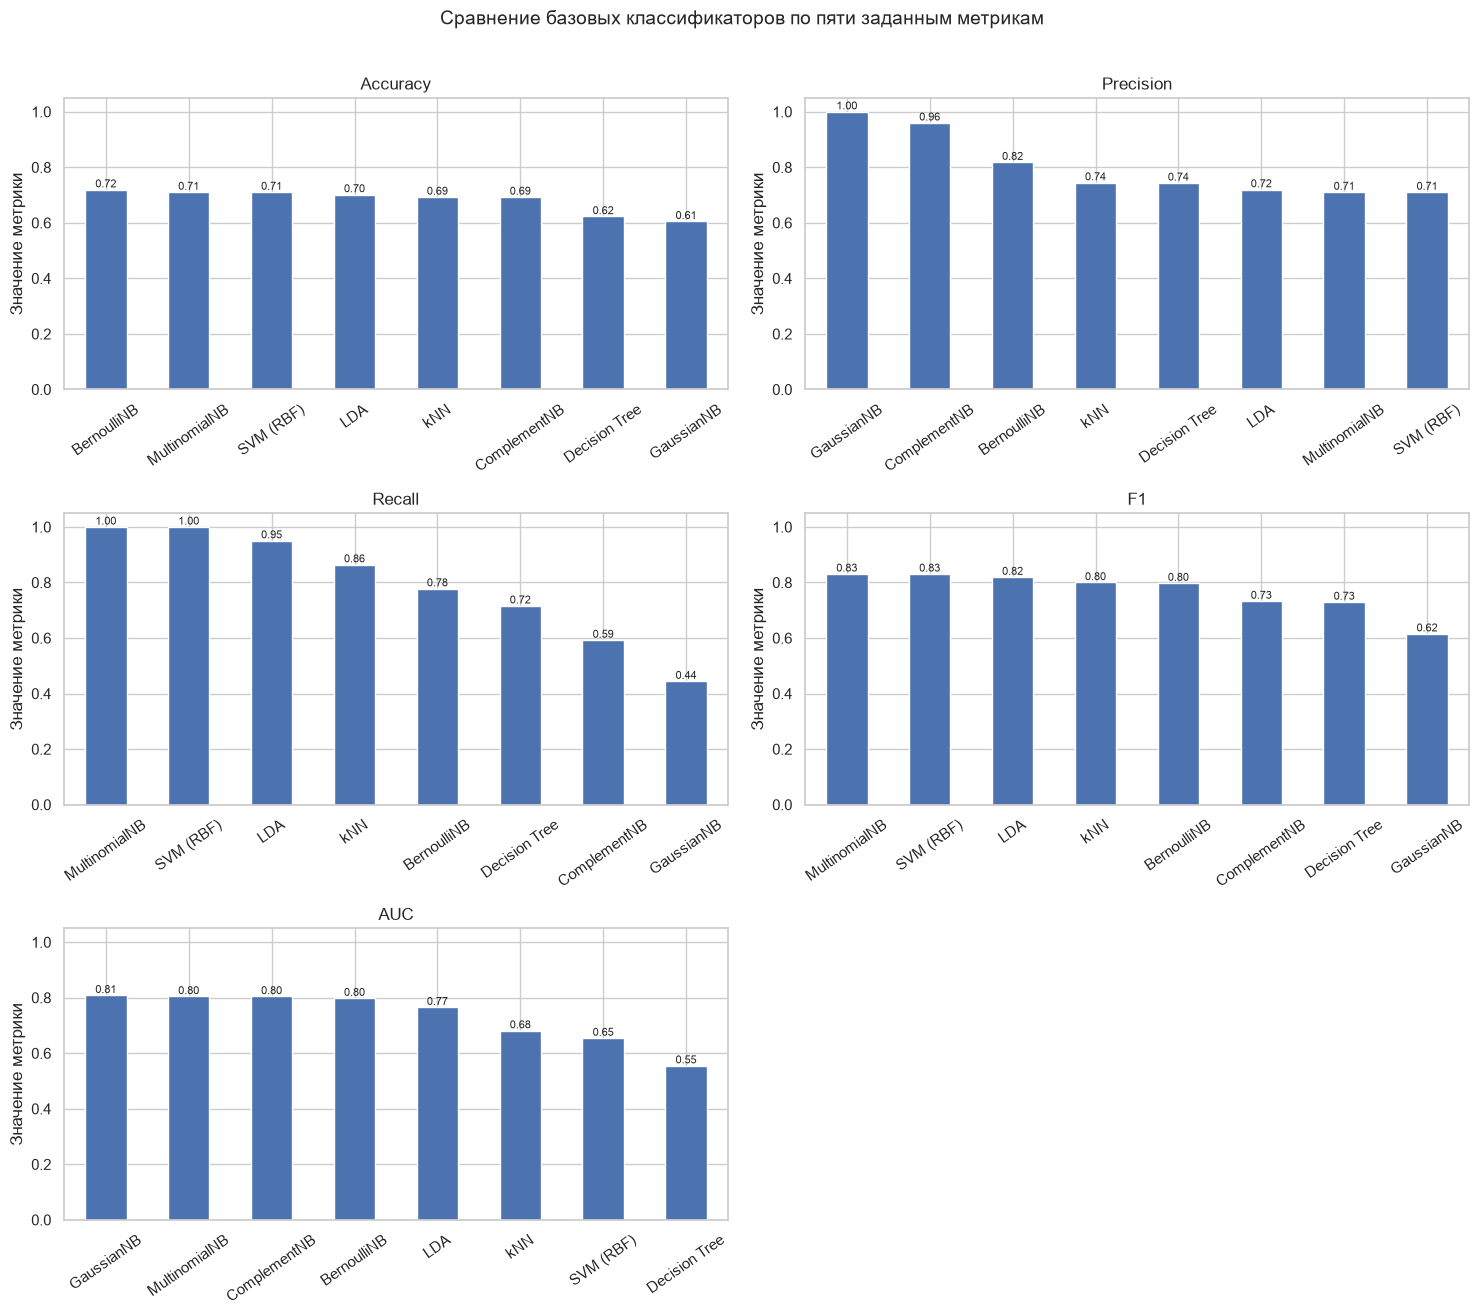

Лидеры по каждой метрике:
  Accuracy: BernoulliNB = 0.719
  Precision: GaussianNB = 1.000
  Recall: MultinomialNB = 1.000
  F1: MultinomialNB = 0.831
  AUC: GaussianNB = 0.808


In [30]:
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']
fig, axes = plt.subplots(3, 2, figsize=(15, 13))
for ax, metric in zip(axes.flat, metrics_to_plot):
    values = baseline_df[metric].sort_values(ascending=False)
    values.plot(kind='bar', ax=ax)
    ax.set_title(metric)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel('Значение метрики')
    ax.tick_params(axis='x', rotation=35)
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.2f}', (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom', fontsize=8)
axes.flat[-1].axis('off')
fig.suptitle('Сравнение базовых классификаторов по пяти заданным метрикам', y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

print('Лидеры по каждой метрике:')
for metric in metrics_to_plot:
    best_name = baseline_df[metric].idxmax()
    print(f'  {metric}: {best_name} = {baseline_df.loc[best_name, metric]:.3f}')

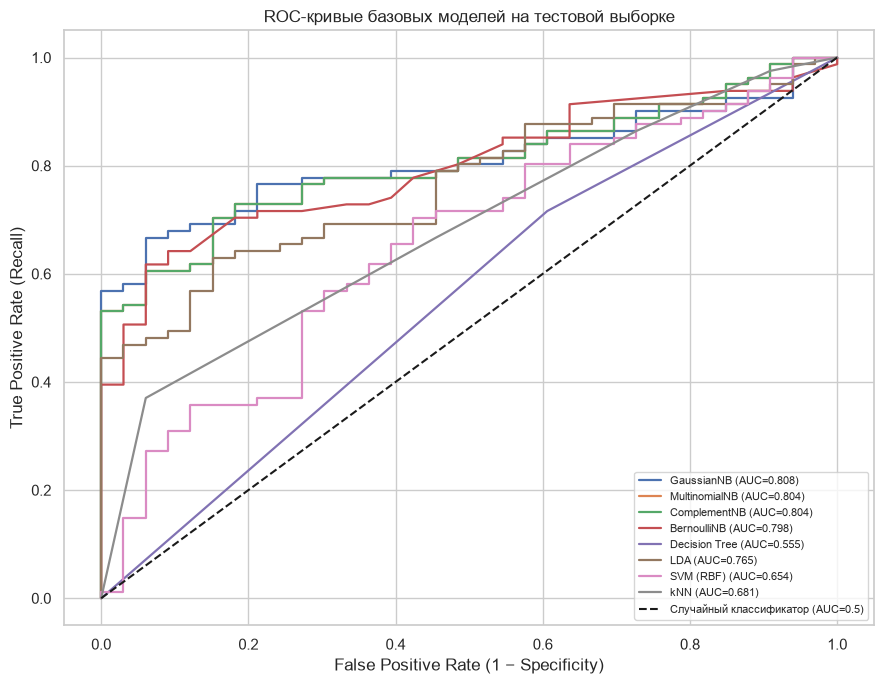

Максимальный AUC среди базовых моделей: 0.808 — GaussianNB


In [31]:
plt.figure(figsize=(9, 7))
for name, model in fitted_base.items():
    fpr, tpr, _ = roc_curve(y_test, get_score(model, X_test))
    plt.plot(fpr, tpr, linewidth=1.6, label=f'{name} (AUC={baseline_df.loc[name, "AUC"]:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Случайный классификатор (AUC=0.5)')
plt.xlabel('False Positive Rate (1 − Specificity)')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC-кривые базовых моделей на тестовой выборке')
plt.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()
print('Максимальный AUC среди базовых моделей:', f'{baseline_df.AUC.max():.3f}', '—', baseline_df.AUC.idxmax())

## Настройка гиперпараметров

### GaussianNB  

Изменяемые параметры:


### MultinomialNB

Изменяемые параметры:


### ComplementNB

Изменяемые параметры:


### BernoulliNB

Изменяемые параметры:


### Decision Tree

Изменяемые параметры:


### Linear Discriminant Analysis

Изменяемые параметры:

### Support Vector Machines

Изменяемые параметры:


### k-Nearest Neighbors

Изменяемые параметры:

## Нейронная сеть на TensorFlow

## Сравнительный анализ

### Таблица сравнения метрик качества для всех рассмотренных методов классификации

## Заключение